# Regional Curve Standardization with dplPy

Most detrending fits a separate growth curve to each series and divides it out. That
works for closed-canopy, uniform-age stands, but it has a cost: a curve fit to one
series cannot tell a slow climate trend from the tree's own growth trend, so it
removes both. Any climate signal longer than the individual segments is lost. This is
the **segment-length curse**.

**Regional Curve Standardization (RCS)** breaks the curse. Instead of one curve per
series, it aligns every series by *cambial age* (rings counted from the pith), averages
them into a single **regional curve** that describes the average biological growth
trend for the site, and divides each series by the slice of that one curve matching its
own ages. Because the regional curve is common to all trees, climate trends longer than
any single series survive. RCS is the method of choice for long, composite, and
**subfossil** collections, where recovering multi-centennial climate is the whole point.

dplPy offers four members of the RCS family:

- **`rcs`** — the classic single regional curve.
- **`sfrcs`** — *signal-free* RCS, which removes the common climate signal's imprint on
  the regional curve before standardizing.
- **`mrcs`** — *multiple*-curve RCS, one regional curve per growth-rate class.
- **`sfmrcs`** — signal-free multiple-curve RCS, the two ideas combined.

This notebook works through all four on a real subfossil collection: the Taimyr (TAI)
Siberian larch set from Büntgen et al. (2021), read straight from the ITRDB. It is 356
series spanning 207 BC to AD 2011 — exactly the kind of long, composite material RCS is
built for. Along the way we poke the functions a little, since they are new.

In [1]:
import dplpy as dpl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

%matplotlib inline
dpl.__version__

'0.8.0'

## 1. Read the collection from the ITRDB

`readers` takes a URL, so we pull the Taimyr file directly from the NOAA archive. Swap
the site code in the URL for another Büntgen 2021 site (for example `NYA_all.rwl`, the
largest) to run the same notebook on different data.

In [2]:
URL = "https://www.ncei.noaa.gov/pub/data/paleo/treering/reconstructions/buentgen2021/TAI_all.rwl"
rwl = dpl.readers(URL)

TAI_all.rwl successfully extracted as rwl file with 356 series covering the period from -207 to 2011


In [ ]:
rwl.shape # (years, number of series) - this is a large and long collection

(2219, 356)

## 2. Check for oddities

Before standardizing anything, screen the collection with `dpl.check`. For a subfossil
larch set we expect a lot of **zero rings** (locally absent rings, a real and common
feature of these trees), so those show up as notes, not errors.

In [4]:
findings = dpl.check(rwl)
findings.groupby(["group", "severity"]).size()

group        severity
crossdating  note         1
             warning     14
zeros        note        83
dtype: int64

The zero-ring notes are the locally absent rings, which are genuine data and are kept.
The crossdating group flags a handful of series that fit the collection less well than
the rest — worth a look in a real study, but not a barrier to the demonstration here.
Indeed, most of these aren't too concerning, except series `03 236`, which deserves closer scrutiny.

In [ ]:
findings[findings["group"] == "crossdating"][["series", "check", "value", "message"]] # show all the crossdating flagged series

,series,check,value,message
0,03 236,RWL_SERIES_OUTLIER,-0.097646,correlates with the collection at r = -0.098 w...
1,04 236,RWL_SERIES_OUTLIER,0.322048,correlates with the collection at r = 0.322 wh...
2,09 236,RWL_SERIES_OUTLIER,0.406689,correlates with the collection at r = 0.407 wh...
3,D007,RWL_SERIES_OUTLIER,0.394581,correlates with the collection at r = 0.395 wh...
4,R021,RWL_SERIES_OUTLIER,0.452769,correlates with the collection at r = 0.453 wh...
5,R101,RWL_SERIES_OUTLIER,0.426310,correlates with the collection at r = 0.426 wh...
6,bav39d,RWL_SERIES_OUTLIER,0.418089,correlates with the collection at r = 0.418 wh...
7,d41kad,RWL_SERIES_OUTLIER,0.410108,correlates with the collection at r = 0.410 wh...
8,pp2m4d,RWL_SERIES_OUTLIER,0.350079,correlates with the collection at r = 0.350 wh...
9,pp2m5d,RWL_SERIES_OUTLIER,0.384810,correlates with the collection at r = 0.385 wh...


## 3. Verify the collection crossdates

These are published, already-crossdated data, so this is a sanity check rather than a
re-dating. The mean interseries correlation is the single number that summarizes how
strongly the series share a common signal; a healthy site sits around 0.5 or higher.

In [ ]:
mean_corr, _ = dpl.interseries_corr(rwl)
mean_corr # collection-wide mean interseries correlation

0.667

## 4. A note on pith offsets

RCS aligns series by cambial age, so in principle it needs each series' **pith offset** —
how many rings are missing between the innermost measured ring and the true pith. This
file ships no offset table, so we use dplPy's default: every series is treated as
pith-present (`po=0`), aligning by the first measured ring. That is the standard
fallback when offsets are not archived, and it is what most published RCS chronologies
without pith estimates assume.

If you *do* have offsets, pass them as `po=` (a `{series: offset}` map or a two-column
table). dplPy's `pith_offset` is a true offset: `0` means the pith is present. (dplR's
`po` is the cambial age of the first ring, where `1` means pith present, so subtract 1
from a dplR table.)

## 5. `rcs`: the single regional curve

`rcs` fits one regional curve to the age-aligned collection and divides each series by
it. The defaults are dplPy's modern choices: an **age-dependent spline** for the curve
(`fit="AgeDepSpline"`), the **ratio** method (`method="ratio"`), and a non-increasing
old-age end (`pos_slope=False`, faithful to ARSTAN and CRUST). `plot=True` draws
dplPy's RCS figure: the regional curve and the resulting chronology.

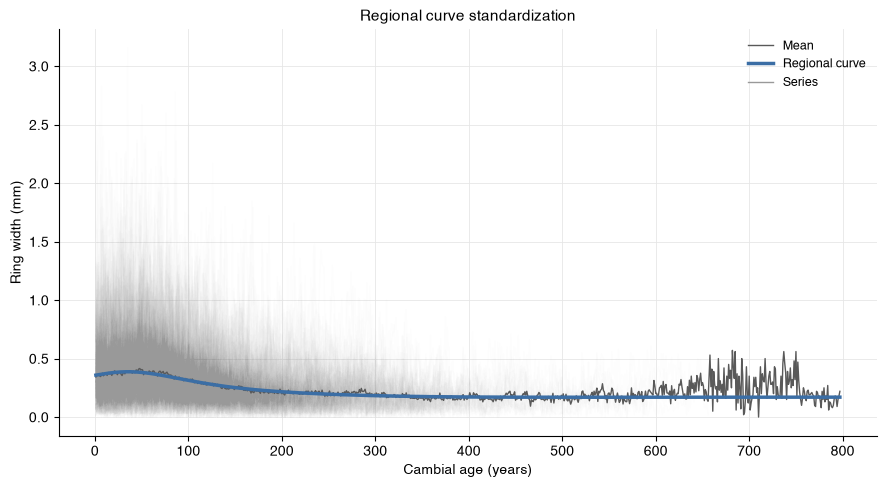

In [7]:
rwi_rcs = dpl.rcs(rwl, plot=True)
plt.show()

The regional curve itself is the heart of the method. We can include it in the output by adding
`rc_out=True` to the input parameters and then plot it against cambial age — the classic negative-exponential-like
decline of ring width as a tree grows older.

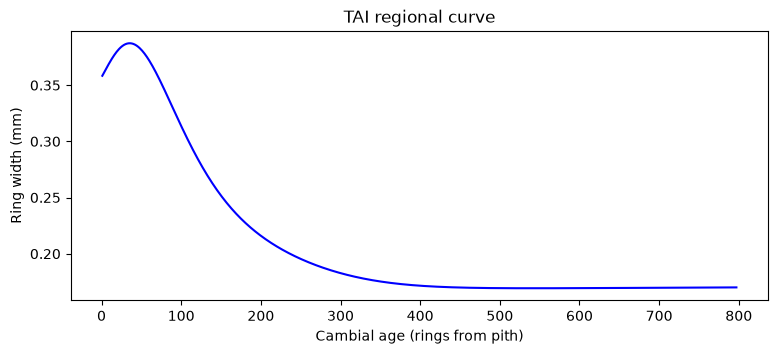

In [25]:
out = dpl.rcs(rwl, rc_out=True, plot=False)
rc = out["rc"] # from the output, extract just the regional curve

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, len(rc) + 1), rc, color="b") # plot just the regional curve
plt.xlabel("Cambial age (rings from pith)"); plt.ylabel("Ring width (mm)")
plt.title("TAI regional curve")
plt.show()

### Poking `rcs`: ratio vs difference, and the old-age slope

Two switches are worth seeing. `method="difference"` subtracts the curve instead of
dividing by it (the variance-stabilized choice); `pos_slope=True` lets the regional
curve rise again at great age instead of being held non-increasing. We compare the
regional curves under the default and `pos_slope=True`.

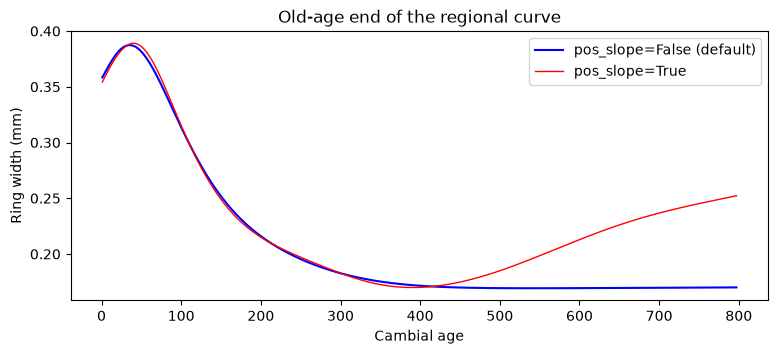

In [26]:
rc_default = dpl.rcs(rwl, rc_out=True, plot=False)["rc"] # appending the ["rc"] at the end returns only the regional curve
rc_posslope = dpl.rcs(rwl, pos_slope=True, rc_out=True, plot=False)["rc"] # appending the ["rc"] at the end returns only the regional curve

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, len(rc_default) + 1), rc_default, color="b", label="pos_slope=False (default)")
plt.plot(np.arange(1, len(rc_posslope) + 1), rc_posslope, color="r", lw=1, label="pos_slope=True")
plt.xlabel("Cambial age"); plt.ylabel("Ring width (mm)"); plt.title("Old-age end of the regional curve")
plt.legend()
plt.show()

In [ ]:
# ratio and difference give different indices; both are valid, for different aims
rwi_ratio = dpl.rcs(rwl, method="ratio", plot=False) # divide series by regional curve
rwi_diff = dpl.rcs(rwl, method="difference", plot=False) # subtract regional curve from series
rwi_ratio.mean(axis=1).mean(), rwi_diff.mean(axis=1).mean()   # ratios (division) center near 1, differences (subtraction) near 0

(np.float64(1.0884405564083905), np.float64(0.021503073348939437))

## 6. `sfrcs`: signal-free RCS

There is a subtlety in RCS. The regional curve is an average over all series, so a strong
common climate signal leaves its fingerprint *in the curve itself*, which then gets
divided back out of the indices — biasing the result, especially the low-frequency trend
and the recent end where sample depth changes. **Signal-free** standardization
(Melvin & Briffa) breaks the circularity: it estimates the curve, removes the common
signal, re-estimates the curve from the signal-free series, and iterates until the curve
stops changing.

`sfrcs` runs that iteration around the RCS curve.

Signal-free RCS converged in 4 iterations (max change 5.95e-04 < 0.001).


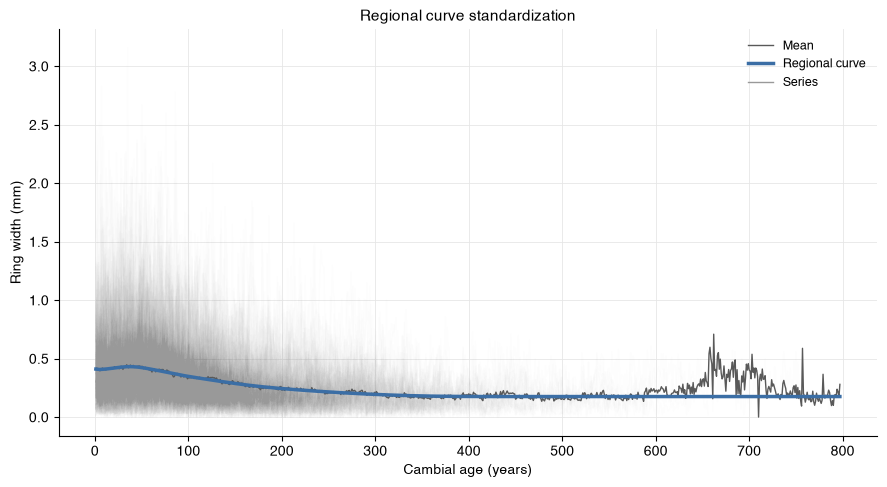

In [11]:
rwi_sfrcs = dpl.sfrcs(rwl, plot=True)
plt.show()

### The signal-free curve, side by side

Plotting the two regional curves together shows what the signal-free pass changed. On
TAI the curves are close, so the common signal left only a modest imprint, but they
separate at the young, fast-growth end, where the signal-free estimate sits a little
higher. That difference is small in millimetres yet it is exactly the kind of low-frequency
adjustment that carries through into the chronology.

Signal-free RCS converged in 4 iterations (max change 5.95e-04 < 0.001).


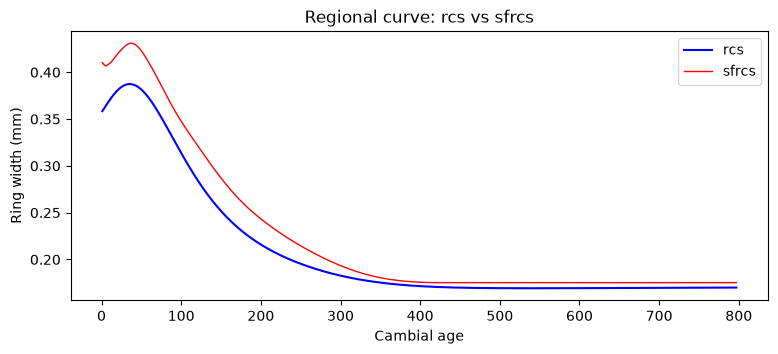

In [28]:
rc_rcs = dpl.rcs(rwl, rc_out=True, plot=False)["rc"]
rc_sfrcs = dpl.sfrcs(rwl, return_info=True, plot=False)["rc"]   # signal-free curve

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, len(rc_rcs) + 1), rc_rcs, color="b", label="rcs")
plt.plot(np.arange(1, len(rc_sfrcs) + 1), rc_sfrcs, color="r", lw=1, label="sfrcs")
plt.xlabel("Cambial age"); plt.ylabel("Ring width (mm)"); plt.title("Regional curve: rcs vs sfrcs")
plt.legend()
plt.show()

## 7. `mrcs`: multiple regional curves

A single regional curve assumes every tree follows the *same* average growth trend. But
fast- and slow-growing trees have differently shaped curves, and if the mix of
fast- and slow-growers changes over time — as it does when a subfossil collection shifts
from one period to another — a single average curve injects a spurious trend. This is
**modern (or differing-contemporaneous) sample bias**.

`mrcs` (the CRUST approach of Melvin & Briffa) sorts the trees by growth rate, splits
them into `n_curves` equal classes, and builds one regional curve per class. Each tree is
standardized by the curve for its own class.

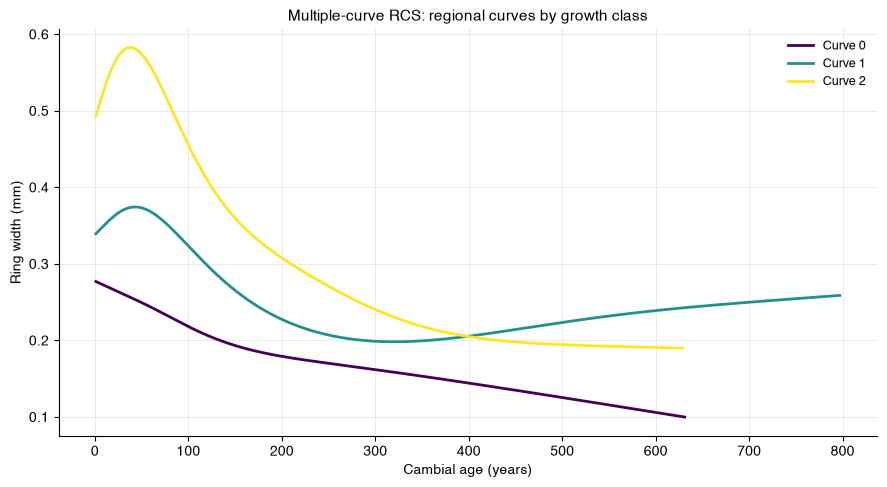

In [13]:
rwi_mrcs = dpl.mrcs(rwl, n_curves=3, plot=True)
plt.show()

The point of `mrcs` is clearest when we overlay the class curves on the single curve.
The fast-growth class sits well above the slow-growth class; the single curve is a blend
whose shape depends on how many of each are in the sample at a given time.

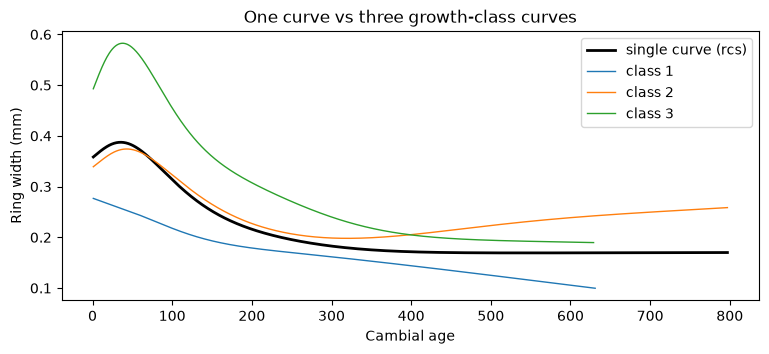

In [14]:
mout = dpl.mrcs(rwl, n_curves=3, rc_out=True, plot=False)
curves = mout["rc"]                    # one regional curve per growth class

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, len(rc) + 1), rc, color="black", lw=2, label="single curve (rcs)")
for k, c in enumerate(curves):
    plt.plot(np.arange(1, len(c) + 1), c, lw=1, label=f"class {k + 1}")
plt.xlabel("Cambial age"); plt.ylabel("Ring width (mm)"); plt.title("One curve vs three growth-class curves")
plt.legend()
plt.show()

In [ ]:
# how many trees landed in each growth class?
pd.Series(mout["alloc"]).value_counts().sort_index() 

0    119
1    119
2    118
Name: count, dtype: int64

## 8. `sfmrcs`: signal-free multiple-curve RCS

The two refinements are independent, so they combine: `sfmrcs` runs the signal-free
iteration around the multiple-curve allocation. It is the most elaborate member of the
family.

Signal-free RCS converged in 4 iterations (max change 5.03e-04 < 0.001).


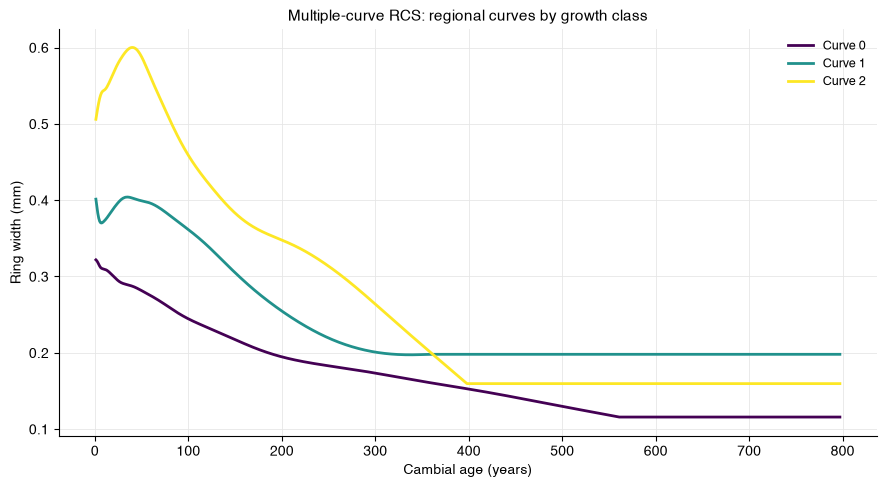

In [16]:
rwi_sfmrcs = dpl.sfmrcs(rwl, n_curves=3, plot=True)
plt.show()

## 9. The family nests

`mrcs` and `sfmrcs` are strict generalizations: with a single class they must reduce
*exactly* to `rcs` and `sfrcs`. This is both a design property worth knowing and a
correctness check worth running.

In [17]:
a = dpl.mrcs(rwl, n_curves=1, plot=False)
b = dpl.rcs(rwl, plot=False)
print("mrcs(n_curves=1) == rcs    max abs diff:", float(np.nanmax(np.abs(a.values - b.values))))

c = dpl.sfmrcs(rwl, n_curves=1, plot=False)
d = dpl.sfrcs(rwl, plot=False)
print("sfmrcs(n_curves=1) == sfrcs max abs diff:", float(np.nanmax(np.abs(c.values - d.values))))

mrcs(n_curves=1) == rcs    max abs diff: 0.0
Signal-free RCS converged in 4 iterations (max change 5.95e-04 < 0.001).
Signal-free RCS converged in 4 iterations (max change 5.95e-04 < 0.001).
sfmrcs(n_curves=1) == sfrcs max abs diff: 0.0


## 10. Comparing the four chronologies

The real test is what the chronologies look like. We build a standard chronology from
each set of indices with `chron`, then overlay them. To see the low-frequency behaviour —
the part RCS exists to preserve — we smooth each with a 20-year running mean and show the
well-replicated portion (sample depth at least five series).

In [18]:
variants = {
    "rcs": rwi_rcs,
    "sfrcs": rwi_sfrcs,
    "mrcs (3)": rwi_mrcs,
    "sfmrcs (3)": rwi_sfmrcs,
}

crns = {name: dpl.chron(rwi, plot=False) for name, rwi in variants.items()}

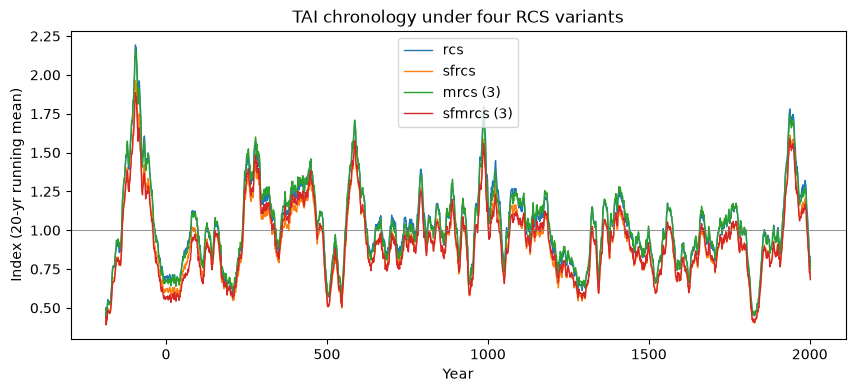

In [19]:
plt.figure(figsize=(10, 4))
for name, crn in crns.items():
    well = crn[crn["samp_depth"] >= 5]           # drop thinly-replicated ends
    plt.plot(well.index, well["std"].rolling(20, center=True).mean(), lw=1, label=name)
plt.axhline(1.0, color="grey", lw=0.6)
plt.xlabel("Year"); plt.ylabel("Index (20-yr running mean)")
plt.title("TAI chronology under four RCS variants")
plt.legend()
plt.show()

The four chronologies agree on the high-frequency, year-to-year signal and diverge
mostly (although still minimally) in the low-frequency trend — which is exactly where the method choice matters.
Signal-free standardization and multiple curves each adjust the long-term shape, and the
differences you see are the sample-bias corrections those methods are designed to make.

## Choosing among them

- **`rcs`** — the baseline. One regional curve, the method's original form.
- **`sfrcs`** — when you want to remove the common signal's bias from the curve,
  especially for the low-frequency trend and the recent end.
- **`mrcs`** — when the growth-rate mix of the sample changes through time, which risks a
  spurious trend from a single blended curve.
- **`sfmrcs`** — both corrections at once.

All four share the same `fit`, `method`, `period`, and `pos_slope` vocabulary as
`detrend` and `rcs`, so anything you learned tuning one carries over. Pith offsets, when
you have them, go in `po=` and matter most for the shape of the young end of every curve.

See the [detrending and standardization guide](https://opendendro.github.io/dplPy/guide/detrending-standardization/)
for the curve-fitting options, and the fidelity notes for how dplPy's RCS follows ARSTAN
and CRUST.